# Aula 0 — Configuração do ambiente e organização dos dados
**GeoCiS · Análise espectral de solos em Python** · *uso interno — não compartilhar dados*

**Objetivos**
1. Conferir o ambiente (Python, VSCode, bibliotecas);
2. Entender a estrutura do projeto e do pacote `geocis_espectral`;
3. Carregar a base pareada **VIS–NIR–SWIR + MIR** e conhecer os atributos laboratoriais.

> **Dados:** `raw_nir_data_Saturin.csv` e `raw_mir_data_Saturin.csv`, procurados em `data/raw/`
> ou na pasta-mãe do projeto. Na primeira execução a base pareada é montada automaticamente
> (~30 s) e salva em `data/processed/`; depois carrega em segundos.

## 1. Estrutura do projeto

```
geocis-espectroscopia/
├── geocis_espectral/      ← pacote com as rotinas reutilizáveis (importado nas aulas)
│   ├── dados.py           ← leitura, base pareada, dados sintéticos
│   ├── visualizacao.py    ← Módulo 1
│   ├── processamento.py   ← Módulo 2
│   ├── exploratoria.py    ← Módulo 3
│   ├── agrupamento.py     ← Módulo 4
│   └── modelagem.py       ← Módulo 5 (ML + SHAP)
├── notebooks/             ← aulas (este arquivo)
├── scripts/               ← preparar_dados.py, pipeline_modelagem.py (tradução do R)
├── data/raw | processed   ← dados (fora do Git!)
├── outputs/               ← figuras, tabelas, modelos (fora do Git)
└── tests/                 ← testes automáticos (python -m pytest)
```

**Regra de ouro:** a lógica fica no pacote (`.py`), os notebooks só *chamam* as funções e
mostram resultados. Assim, a mesma rotina é reaproveitada em qualquer projeto do grupo.

In [1]:
import sys, platform
print("Python", sys.version.split()[0], "|", platform.system())
import numpy, pandas, scipy, sklearn, matplotlib, shap, xgboost
for m in (numpy, pandas, scipy, sklearn, matplotlib, shap, xgboost):
    print(f"{m.__name__:<12} {m.__version__}")

Python 3.14.3 | Windows


C:\Users\PC\Desktop\RESET\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy        2.4.3
pandas       3.0.1
scipy        1.17.1
sklearn      1.8.0
matplotlib   3.10.8
shap         0.52.0
xgboost      3.4.1


## 2. Carregando a base

In [2]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

Preparando a base pareada a partir de C:\Users\PC\Desktop\RESET (cerca de 30 s)...


Base salva em C:\Users\PC\Desktop\RESET\geocis-espectroscopia\data\processed\base_pareada_vnir_mir.pkl


SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

`ds` é um objeto `SoilSpectra` com três tabelas **alinhadas pelo mesmo índice** (`ID_Unico`):

| atributo | conteúdo | colunas |
|---|---|---|
| `ds.meta` | metadados + atributos laboratoriais | texto/números |
| `ds.vnir` | VIS–NIR–SWIR (reflectância) | comprimento de onda em **nm** (350 → 2500) |
| `ds.mir`  | MIR | número de onda em **cm⁻¹** (4000 → 600, decrescente) |

In [3]:
print(ds.info)
ds.meta.head()

{'fonte_vnir': 'raw_nir_data_Saturin.csv', 'fonte_mir': 'raw_mir_data_Saturin.csv', 'ids_em_comum': 6230, 'descartados_lacunas': 0, 'unidade_vnir': 'nm (reflectância)', 'unidade_mir': 'cm-1'}


,Owner,X,Y,Country,Upper_depth_cm,Lower_depth_cm,Sand_gkg,Silt_gkg,Clay_gkg,Density_kgdm3,C_gkg,OM_gkg,P_mgkg,pH_H2O,Ca_mmolkg,Mg_mmolkg,K_mmolkg,CEC_Ph7_mmolkg,CEC_Efe_mmolkg,MacroN_g_kg,Textura
ID_Unico,,,,,,,,,,,,,,,,,,,,,
1,Sabine Grunwald,78.117561,17.369946,India,NaN,NaN,787.0,123.0,90.0,NaN,12.9,NaN,14.36,8.10,NaN,NaN,NaN,NaN,NaN,NaN,Média
2,Sabine Grunwald,78.117127,17.369520,India,NaN,NaN,538.0,172.0,290.0,NaN,11.3,NaN,3.35,8.00,NaN,NaN,NaN,NaN,NaN,NaN,Média
3,Sabine Grunwald,78.118430,17.370456,India,NaN,NaN,255.0,295.0,450.0,NaN,17.4,NaN,22.12,8.00,NaN,NaN,NaN,NaN,NaN,NaN,Argilosa
4,Sabine Grunwald,78.119818,17.370465,India,NaN,NaN,210.0,240.0,550.0,NaN,17.8,NaN,20.44,8.00,NaN,NaN,NaN,NaN,NaN,NaN,Argilosa
5,Sabine Grunwald,78.120025,17.371776,India,NaN,NaN,236.0,234.0,530.0,NaN,16.6,NaN,15.07,7.91,NaN,NaN,NaN,NaN,NaN,NaN,Argilosa


In [4]:
ds.vnir.iloc[:3, :8]

,350.0,351.0,352.0,353.0,354.0,355.0,356.0,357.0
ID_Unico,,,,,,,,
1,0.061382,0.047321,0.054025,0.062414,0.067614,0.064139,0.057143,0.048991
2,0.012337,0.018576,0.031915,0.039216,0.036964,0.030043,0.026320,0.026257
3,0.054856,0.041434,0.037522,0.040549,0.050495,0.053500,0.046343,0.033506


In [5]:
ds.mir.iloc[:3, :8]

,4000.0,3996.0,3992.0,3988.0,3984.0,3980.0,3976.0,3972.0
ID_Unico,,,,,,,,
1,0.328971,0.328982,0.328739,0.328833,0.329396,0.329039,0.328763,0.328751
2,0.306972,0.306382,0.305910,0.305776,0.306014,0.305989,0.305963,0.305236
3,0.384089,0.383667,0.383035,0.382030,0.381971,0.382019,0.381202,0.380388


### Eixo espectral e conversão de unidades
λ (nm) = 10⁷ / ν (cm⁻¹). O MIR 4000–600 cm⁻¹ corresponde a 2500–16 667 nm — começa
exatamente onde termina o SWIR.

In [6]:
print("VIS-NIR-SWIR:", ds.vnir.columns.min(), "-", ds.vnir.columns.max(), "nm; passo",
      np.diff(ds.vnir.columns[:2])[0], "nm;", ds.vnir.shape[1], "bandas")
print("MIR:", ds.mir.columns.max(), "-", ds.mir.columns.min(), "cm-1; passo",
      abs(np.diff(ds.mir.columns[:2])[0]), "cm-1;", ds.mir.shape[1], "bandas")
print("MIR em nm:", pp.wavenumber_to_nm([ds.mir.columns.max(), ds.mir.columns.min()]).round(0))

VIS-NIR-SWIR: 350.0 - 2500.0 nm; passo 1.0 nm; 2151 bandas
MIR: 4000.0 - 600.0 cm-1; passo 4.0 cm-1; 851 bandas
MIR em nm: [ 2500. 16667.]


## 3. Atributos laboratoriais: o que temos e quanto falta

In [7]:
desc = ex.describe_attributes(ds.attributes)
desc

,n,mean,std,min,25%,50%,75%,max,cv_%,assimetria
Sand_gkg,5475.0,367.49,270.44,0.00,124.00,326.00,569.00,996.00,73.59,0.49
Silt_gkg,5526.0,311.39,188.38,0.00,162.00,282.00,450.00,905.00,60.50,0.51
Clay_gkg,5541.0,313.89,210.30,0.00,150.00,288.00,451.00,968.00,67.00,0.59
Density_kgdm3,1437.0,1.09,0.42,0.06,0.89,1.17,1.41,1.89,38.31,-0.81
C_gkg,2749.0,78.36,144.70,0.10,7.30,14.40,40.60,582.26,184.67,2.09
P_mgkg,1384.0,13.37,20.89,0.00,2.88,5.70,15.72,288.00,156.20,4.69
pH_H2O,5696.0,6.50,1.44,1.67,5.20,6.59,7.81,10.50,22.21,-0.07
Ca_mmolkg,2980.0,122.72,159.74,1.00,12.00,57.00,176.00,1682.00,130.17,2.31
Mg_mmolkg,2878.0,33.33,49.71,1.00,5.00,15.00,40.00,680.00,149.16,3.80
K_mmolkg,3165.0,4.60,8.13,0.00,1.00,2.14,5.00,187.77,176.80,10.61


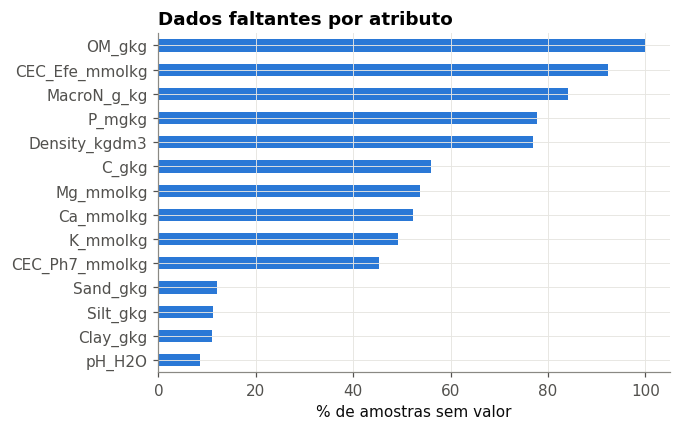

In [8]:
faltantes = (ds.attributes.isna().mean() * 100).round(1).sort_values()
ax = faltantes.plot.barh(figsize=(6, 4), color=vz.CATEGORICAL[0])
ax.set_xlabel("% de amostras sem valor")
ax.set_title("Dados faltantes por atributo", loc="left");

**Atenção:** cada atributo tem um *n* diferente. Nas próximas aulas, os modelos e correlações
de um atributo usam somente as amostras com aquele valor (`ds.dropna_attribute("Clay_gkg")`).

In [9]:
pd.concat({"amostras": ds.meta["Owner"].value_counts()}, axis=1)

,amostras
Owner,
ICRAF.ISRIC,3481
Sabine Grunwald,912
R. Poppiel / Dematte,844
KSSL.SSL,521
LUCAS_Europe,472


In [10]:
ds.meta["Textura"].value_counts(dropna=False)

Textura
Média             2796
Argilosa          1562
NaN                689
Muito argilosa     620
Arenosa            563
Name: count, dtype: int64

## 4. Selecionando subconjuntos

`ds.subset(...)` aceita máscara booleana ou lista de IDs e devolve outro `SoilSpectra` coerente
(meta + espectros). `ds.sample(n)` sorteia `n` amostras — útil para testar código rápido.

In [11]:
argilosos = ds.subset(ds.meta["Clay_gkg"].to_numpy() > 350)
pequeno = ds.sample(300)
print(argilosos)
print(pequeno)

SoilSpectra(n=2166, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])
SoilSpectra(n=300, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])


### Matriz única VIS–NIR–SWIR seguido do MIR
Para modelos com fusão das duas faixas, `ds.combined()` concatena as colunas
(`vnir_350 … vnir_2500, mir_4000 … mir_600`).

In [12]:
ds.combined().iloc[:2, [0, 1, 2149, 2150, 2151, 2152, -1]]

,vnir_350,vnir_351,vnir_2499,vnir_2500,mir_4000,mir_3996,mir_600
ID_Unico,,,,,,,
1,0.061382,0.047321,0.193580,0.193959,0.328971,0.328982,0.041059
2,0.012337,0.018576,0.126098,0.125454,0.306972,0.306382,0.036933


## Exercícios
1. Quantas amostras têm **argila e carbono** medidos simultaneamente?
2. Crie um subconjunto só com amostras de um `Owner` e compare a média de argila com a base toda.
3. Converta 2200 nm e 1000 cm⁻¹ para a outra unidade.